# Hierarchical Edge Bundling

**Family:** Flow &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Advanced

> *Flow:* Show the volume or intensity of movement between states, stages, or places.

## Design purpose

Leaves of a hierarchy sit around a circle, grouped by parent. Each connection is drawn as a B-spline routed through the hierarchy (leaf → parent → root → parent → leaf), so edges between the same groups bundle into a shared "cable". This turns the hairball of a dense network into readable group-to-group traffic while keeping every individual link.

## When to use

- Show many connections (100s) between items that belong to a known hierarchy
- Reveal which groups depend on which, e.g. module imports, interbank exposures, team communication
- Find unexpected links that leave their group's main bundle

## Avoid when

- There is no meaningful hierarchy to route edges through (use a force-directed network or matrix)
- Readers need exact weights or the direction of every edge (use an adjacency matrix)
- Only a handful of edges exist (a plain network or arc diagram is simpler)

## Alternatives

- Adjacency matrix (ordered)
- Chord diagram (group-level totals only)
- Network graph (force-directed)

## Design tips

- Bundling strength β (0.7–0.9) trades readability for faithfulness: β=1 follows the hierarchy exactly, β=0 is a straight line
- Color edges by source group; keep them thin and semi-transparent so bundles read by density
- Rotate leaf labels radially and keep the inner area free of text

## Example

Simulated import dependencies between 36 modules of a trading platform, grouped into six packages (data, pricing, risk, execution, reporting, api). Edges are colored by the importing package.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from scipy.interpolate import BSpline

### Data

In [2]:
rng = np.random.default_rng(21)
packages = ["data", "pricing", "risk", "execution", "reporting", "api"]
modules = {p: [f"{p}.{m}" for m in rng.choice(
    ["core", "io", "cache", "models", "utils", "config", "engine", "calc", "store", "feed", "api", "views"],
    6, replace=False)] for p in packages}
# How likely a module in package A imports a module in package B
pref = pd.DataFrame(0.02, index=packages, columns=packages)
for a, b, p in [("pricing", "data", 0.35), ("risk", "data", 0.30), ("risk", "pricing", 0.30),
                ("execution", "risk", 0.25), ("execution", "pricing", 0.20), ("reporting", "risk", 0.25),
                ("reporting", "data", 0.15), ("api", "pricing", 0.15), ("api", "risk", 0.15),
                ("api", "execution", 0.20), ("api", "reporting", 0.15)]:
    pref.loc[a, b] = p
for p in packages:
    pref.loc[p, p] = 0.25
edges = [(a, b, pa) for pa in packages for pb in packages
         for a in modules[pa] for b in modules[pb]
         if a != b and rng.random() < pref.loc[pa, pb]]
edges = pd.DataFrame(edges, columns=["source", "target", "package"])
edges["package"].value_counts()

package
api          32
risk         31
execution    25
reporting    25
pricing      18
data         17
Name: count, dtype: int64

### Plot

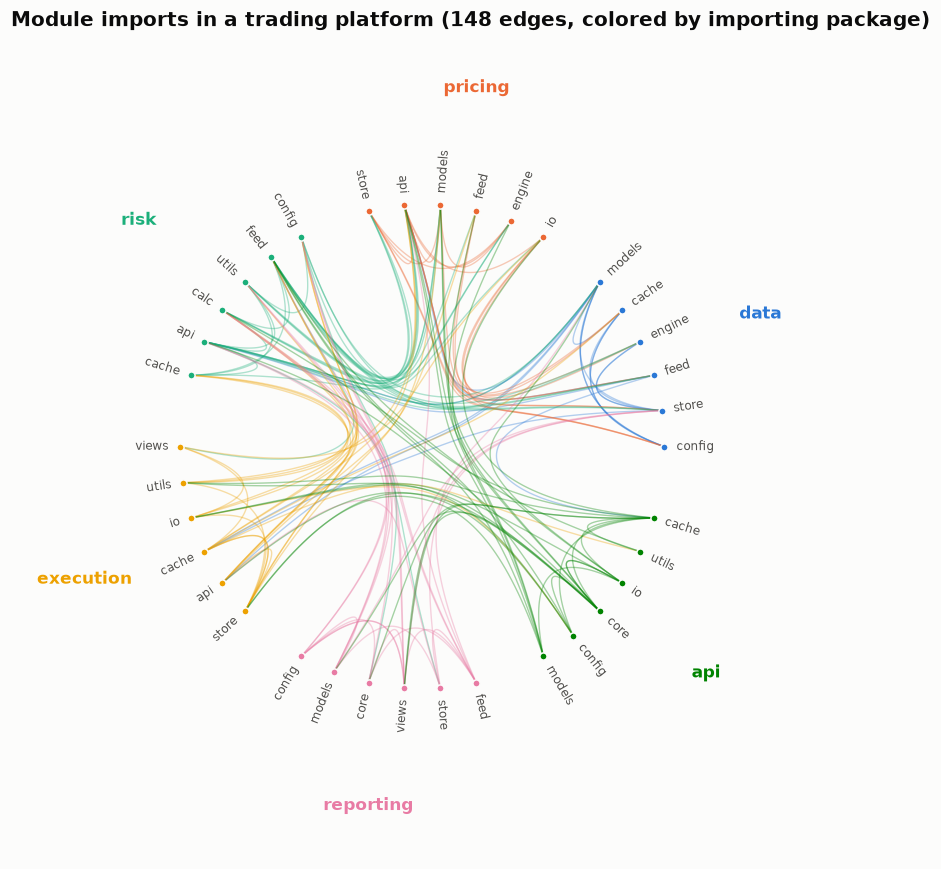

In [3]:
# Layout: leaves on the unit circle grouped by package, package nodes at r=0.45, root at the centre
leaves = [m for p in packages for m in modules[p]]
gap = 1.0                                     # empty slot between packages
slots = len(leaves) + gap * len(packages)
angle, pos, k = {}, {}, 0.0
for p in packages:
    for m in modules[p]:
        angle[m] = 2 * np.pi * k / slots
        pos[m] = np.array([np.cos(angle[m]), np.sin(angle[m])])
        k += 1
    k += gap
for p in packages:
    a = np.mean([angle[m] for m in modules[p]])
    pos[p] = 0.45 * np.array([np.cos(a), np.sin(a)])
pos["root"] = np.zeros(2)
pkg_of = {m: p for p in packages for m in modules[p]}
color = dict(zip(packages, PALETTE))


def bundled_path(a, b, beta=0.85, n=80):
    pa, pb = pkg_of[a], pkg_of[b]
    via = [a, pa, b] if pa == pb else [a, pa, "root", pb, b]
    P = np.array([pos[v] for v in via])
    # Straighten control points towards the chord by (1 - beta) (Holten 2006)
    t = np.linspace(0, 1, len(P))[:, None]
    P = beta * P + (1 - beta) * (P[0] + t * (P[-1] - P[0]))
    deg = min(3, len(P) - 1)
    knots = np.r_[[0] * deg, np.linspace(0, 1, len(P) - deg + 1), [1] * deg]
    return BSpline(knots, P, deg)(np.linspace(0, 1, n))


fig, ax = plt.subplots(figsize=(8, 8))
for _, e in edges.iterrows():
    xy = bundled_path(e["source"], e["target"])
    ax.plot(xy[:, 0], xy[:, 1], color=color[e["package"]], alpha=0.35, linewidth=0.9)
for m in leaves:
    x, y = pos[m]
    deg = np.degrees(angle[m])
    flip = 90 < deg < 270
    ax.scatter(x, y, s=22, color=color[pkg_of[m]], zorder=3, edgecolor="#fcfcfb", linewidth=1)
    ax.text(1.05 * x, 1.05 * y, m.split(".")[1], rotation=deg + (180 if flip else 0), rotation_mode="anchor",
            ha="right" if flip else "left", va="center", fontsize=8, color="#52514e")
for p in packages:
    a = np.mean([angle[m] for m in modules[p]])
    ax.text(1.5 * np.cos(a), 1.5 * np.sin(a), p, ha="center", va="center", fontsize=11,
            fontweight="bold", color=color[p])
ax.set_xlim(-1.7, 1.7)
ax.set_ylim(-1.7, 1.7)
ax.set_aspect("equal")
ax.axis("off")
ax.set_title(f"Module imports in a trading platform ({len(edges)} edges, colored by importing package)")
fig.tight_layout()
plt.show()

## How to read it

Thick bundles show heavy package-to-package traffic. Pricing and risk modules lean on data, execution depends on risk and pricing, and api reaches into nearly everything. A thin strand that breaks away from its bundle is an unusual cross-package import worth reviewing.

---
Standalone script: [`hierarchical_edge_bundling.py`](hierarchical_edge_bundling.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)